# Laboratorio 4 — Actas municipales en un grafo: Neo4j, recuperación y un modelo de lenguaje

**Curso:** TI-4601 Bases de Datos Avanzados · **Valor:** 2,5 % · **Equipos:** tres personas  
**Clase previa:** *Bases de datos de grafos* (`08-BDGrafos.pptx`)  
**Tiempo estimado:** de 3 a 4 horas

El Concejo Municipal de Belén publica sus actas en un índice público:
[actas municipales](https://www.belen.go.cr/web/guest/actas-municipales). Cada acta registra una sesión: quiénes estuvieron, con qué cargo, qué se discutió y qué se acordó. Preguntas como «¿quién presidió la sesión 61-2026?» o «¿en qué sesiones estuvo esta persona y qué se habló sobre cierto tema?» recorren caminos en el grafo llamados **relaciones**: de una persona a una sesión, y de la sesión a su texto. Cada **nodo** representa una sesión, el texto o personas.

En este laboratorio usted va a:

1. cargar cuatro actas en **Neo4j** como un grafo de propiedades;
2. escribir en **Cypher** las consultas que lo cargan y lo recorren (TODO 1 a 5);
3. recuperar texto por **parecido de significado** con un modelo de *embeddings*;
4. entregar ese texto, junto con información extraída del grafo, a un **modelo de lenguaje** pequeño que redacta la respuesta, orquestado con **LangGraph**.

## Cómo usar este cuaderno

- Ejecute las celdas **en orden**, de arriba hacia abajo (Mayúscula + Enter).
- Las celdas marcadas con **TODO** son las que usted completa. Todo lo demás ya está escrito: léalo, pero no lo modifique.
- Después de cada TODO hay una celda que verifica su trabajo y escribe una de tres cosas:
  - `PENDIENTE: TODO n`: todavía no completó esa celda. El cuaderno sigue sin error.
  - `OK: ...`: la verificación pasó.
  - `VERIFICACIÓN FALLÓ: ...`: la consulta corre, pero el resultado no es el esperado. Lea el mensaje, corrija y vuelva a ejecutar **la celda del TODO y la de verificación**.
- Si algo sale mal, use *Kernel → Restart Kernel and Run All Cells*. El grafo se vacía y se vuelve a cargar en el paso 5.


## 1. Grafos

En la clase se vio que una base de datos de grafos guarda tres cosas:

| Elemento | Qué es | En Cypher | Ejemplo de la clase |
| --- | --- | --- | --- |
| **Nodo** | una entidad | `(variable:Etiqueta)` | `(p:Persona {nombre: "Pedro"})` |
| **Relación** | una conexión con **tipo** y **dirección** | `-[:TIPO]->` | `(p)-[:CALIFICA]->(l)` |
| **Propiedad** | un par clave-valor, en nodos **o en relaciones** | `{clave: valor}` | `[:SABE {nivel: 5}]` |

En clase hablamos de un detalle importante: el **nivel** con que Juan conoce *Machine Learning* no es una propiedad de Juan ni del tema. Es una propiedad **de la relación** entre ambos. En este laboratorio pasa lo mismo con el **cargo**: ser «Presidente» no es una propiedad de la persona, sino de su participación en **una sesión concreta**.


**Modelo relacional frente a grafo** 

Para hacer la consulta «¿Quiénes son los amigos de X?» se necesita un `JOIN` en SQL.  «¿Quiénes son los amigos de los amigos de X?» necesita dos `JOIN`, y así con cada combinación de tablas. En Cypher, cada salto sería el análogo al 'join', que se representa como una flecha más dentro del **mismo patrón**:

```cypher
MATCH (x:Persona {nombre: "X"})-[:AMIGO]->()-[:AMIGO]->(fof)
RETURN fof.nombre
```

Vamos a medir esa diferencia con actas en lugar de amigos.

## 3. Lo nuevo de Cypher en este laboratorio

En la clase se usaron `CREATE` y `MATCH`. Para cargar datos reales hacen falta algunas piezas más:

| Instrucción | Para qué sirve | Ejemplo |
| --- | --- | --- |
| `MERGE` | busca el patrón; si no existe, lo crea. Repetirlo no duplica | `MERGE (p:Persona {nombre: $nombre})` |
| `SET` | asigna o actualiza propiedades | `SET r.rol = $rol` |
| `$parametro` | valor que llega desde Python; evita armar texto a mano | `MATCH (a:Acta {id: $id})` |
| `CONSTRAINT ... IS UNIQUE` | impide dos nodos con la misma clave | `REQUIRE a.id IS UNIQUE` |
| `OPTIONAL MATCH` | como un `LEFT JOIN`: si no hay coincidencia, deja `null` | `OPTIONAL MATCH (f)-[:SIGUE]->(g)` |
| `count()`, `collect()` | agregan filas, como `COUNT` y una lista | `count(f) AS fragmentos` |
| `WITH` | encadena una parte de la consulta con la siguiente | `WITH a, count(f) AS n` |
| índice vectorial | busca los nodos cuyo vector se parece a otro | `db.index.vector.queryNodes(...)` |

**¿Por qué `MERGE` y no `CREATE`?** Si la carga se interrumpe y se vuelve a ejecutar, `CREATE` crea otra vez a la misma persona y el grafo queda con duplicados. `MERGE` hace que repetir la operación produzca el mismo resultado. Eso se llama **idempotencia**.

## 4. Modelos de lenguaje
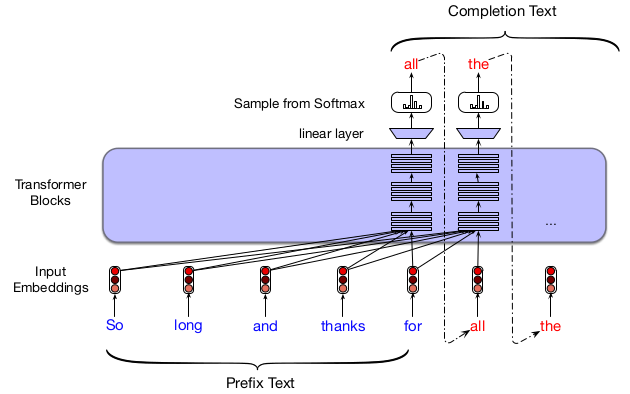

Es una red neuronal entrenada para predecir el siguiente fragmento de texto (un *token*: una palabra o parte de una palabra) a partir de los anteriores. Repitiendo esa predicción, token por token, produce oraciones completas. Tres ideas bastan para este laboratorio:

- **Preentrenado.** El modelo aprendió de una gran cantidad de texto **antes**. No vamos a ajustar el modelo sino que lo usaremos ya preentrenado. La versión *Instruct* de qwen fue entrenada además para seguir instrucciones como «responda usando solo el contexto».
- **Tamaño.** Se mide en parámetros, que son los números que ajustó para codificar los patrones de la tarea de lenguaje. Usamos **Qwen2.5-0.5B-Instruct**, de unos 500 millones de parámetros. Es pequeño a propósito, para que corra en la CPU de una laptop, y por eso se equivoca con más facilidad que los modelos comerciales o frontera.
- **Ventana de contexto.** Es la cantidad de texto que el modelo puede leer en una sola consulta. Lo que no está en esa ventana, el modelo no lo ve.

**Limitaciones del LLM** 

No consulta una base de datos por su cuenta. Solo conoce lo que vio durante el entrenamiento, y las actas de la Municipalidad de Belén del año 2026 no estaban en sus datos de entrenamiento. Cuando le falta información, puede producir una respuesta que **suena** correcta pero no lo es. A eso se le llama **alucinación**. Por eso, en este laboratorio, la respuesta solo vale si se apoya en un texto que **nosotros** le entregamos y que podemos mostrar.

**Modelo de embeddings** 

Es otro tipo de modelo: no redacta texto, sino que convierte un texto en un **vector**, una lista de números. Usamos `paraphrase-multilingual-MiniLM-L12-v2`, que produce vectores de **384** números y funciona en español. Está entrenado para que dos frases con el mismo significado queden con vectores cercanos, aunque usen palabras distintas.

La cercanía se mide con la **similitud coseno**, que vale 1 cuando dos vectores apuntan en la misma dirección y se acerca a 0 cuando no tienen relación:

$$\cos(\theta) = \frac{u \cdot v}{\lVert u \rVert \, \lVert v \rVert}$$

| Modelo | Entra | Sale | Lo usamos para |
| --- | --- | --- | --- |
| `paraphrase-multilingual-MiniLM-L12-v2` | un texto | un vector de 384 números | encontrar fragmentos parecidos a la pregunta |
| `Qwen2.5-0.5B-Instruct` | instrucciones + pregunta + contexto | texto | redactar la respuesta |

Los dos modelos vienen dentro de la imagen de Docker. No se necesita una clave de API ni enviar datos a un servicio externo.

## 4. Modelos de lenguaje



Es una red neuronal entrenada para predecir el siguiente fragmento de texto (un *token*: una palabra o parte de una palabra) a partir de los anteriores. Repitiendo esa predicción, token por token, produce oraciones completas. Tres ideas bastan para este laboratorio:

- **Preentrenado.** El modelo aprendió de una gran cantidad de texto **antes** de llegar a nuestras manos. Aquí no se entrena nada: se usa tal como viene. La versión *Instruct* fue ajustada además para seguir instrucciones como «responda usando solo el contexto».
- **Tamaño.** Se mide en parámetros, que son los números que aprendió. Usamos **Qwen2.5-0.5B-Instruct**, de unos 500 millones de parámetros. Es pequeño a propósito, para que corra en la CPU de una laptop, y por eso se equivoca con más facilidad que los modelos comerciales.
- **Ventana de contexto.** Es la cantidad de texto que el modelo puede leer en una sola consulta. Lo que no está en esa ventana, el modelo no lo ve.

**Lo que un modelo de lenguaje no hace** 

No consulta una base de datos por su cuenta. Solo conoce lo que vio durante el entrenamiento, y las actas de 2026 no estaban ahí. Cuando le falta información, puede producir una respuesta que **suena** correcta pero no lo es. A eso se le llama **alucinación**. Por eso, en este laboratorio, la respuesta solo vale si se apoya en un texto que **nosotros** le entregamos y que podemos mostrar.

**Modelo de embeddings** 

Es otro tipo de modelo: no redacta texto, sino que convierte un texto en un **vector**, una lista de números. Usamos `paraphrase-multilingual-MiniLM-L12-v2`, que produce vectores de **384** números y funciona en español. Está entrenado para que dos frases con el mismo significado queden con vectores cercanos, aunque usen palabras distintas.

La cercanía se mide con la **similitud coseno**, que vale 1 cuando dos vectores apuntan en la misma dirección y se acerca a 0 cuando no tienen relación:

$$\cos(\theta) = \frac{u \cdot v}{\lVert u \rVert \, \lVert v \rVert}$$

| Modelo | Entra | Sale | Lo usamos para |
| --- | --- | --- | --- |
| `paraphrase-multilingual-MiniLM-L12-v2` | un texto | un vector de 384 números | encontrar fragmentos parecidos a la pregunta |
| `Qwen2.5-0.5B-Instruct` | instrucciones + pregunta + contexto | texto | redactar la respuesta |

Los dos modelos vienen dentro de la imagen de Docker. No se necesita una clave de API ni enviar datos a un servicio externo.

## 5. Técnicas de recuperación

*Recuperar* es encontrar, entre todo lo guardado, el texto que sirve para responder una pregunta. Hay tres maneras, y este laboratorio usa las tres:

| Técnica | Cómo funciona | Fortaleza | Debilidad |
| --- | --- | --- | --- |
| **Palabra clave** | busca el texto exacto (`CONTAINS`, `LIKE`) | precisa y fácil de explicar | no encuentra sinónimos: «ratificar» no coincide con «aprobar» |
| **Vectorial** (semántica) | compara el vector de la pregunta con el de cada fragmento | encuentra textos con el mismo significado | puede traer algo **parecido pero equivocado**: el encabezado de otra sesión se parece mucho al de la sesión pedida |
| **Por camino en el grafo** | sigue relaciones explícitas desde un nodo conocido | exacta: el acta 61 está unida solo a *sus* fragmentos y a *sus* participantes | necesita saber desde qué nodo empezar |

**RAG** (*Retrieval-Augmented Generation*, generación aumentada con recuperación) combina recuperación y modelo de lenguaje en tres pasos: **recuperar** fragmentos, **agregarlos** a las instrucciones del modelo y **generar** la respuesta a partir de ellos. El modelo deja de responder «de memoria» y pasa a responder sobre un texto que se puede citar.

**GraphRAG** agrega el grafo a esa receta: además del texto, el contexto incluye **hechos estructurados** que salen de las relaciones. Por ejemplo, «Gilberth González González — cargo: Presidente — en el acta 61-2026». Un modelo pequeño tiene dificultad para encontrar ese dato dentro de un párrafo, pero lo usa bien cuando se lo damos explícito. En el paso 9 usted podrá comprobarlo.

*Lecturas opcionales:* Lewis et al. (2020), *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks*; Edge et al. (2024), *From Local to Global: A Graph RAG Approach to Query-Focused Summarization*.

## 6. Arquitectura del laboratorio

Todo corre en dos contenedores: `ti4601-neo4j` (la base de datos) y `ti4601-lab4` (este cuaderno y los dos modelos).

```mermaid
flowchart TB
  subgraph carga["Carga: se ejecuta una vez"]
    W["Índice web de actas"] --> PDF["4 PDF, 2 páginas de cada uno"]
    PDF --> TXT["Texto (pypdf)"]
    TXT --> PART["Participantes y cargos (expresión regular)"]
    TXT --> SPL["Fragmentos (LlamaIndex)"]
    SPL --> EMB["Vectores de 384 (MiniLM)"]
  end
  PART --> NEO[("Neo4j")]
  EMB --> NEO
  subgraph consulta["Consulta: se ejecuta en cada pregunta"]
    Q["Pregunta"] --> QE["Vector de la pregunta"]
    QE --> R["recuperar: índice vectorial + camino en el grafo"]
    R --> LLM["redactar: Qwen2.5-0.5B-Instruct"]
    LLM --> RESP["Respuesta que cita el acta"]
  end
  NEO <--> R
```

| Pieza | Papel |
| --- | --- |
| **Neo4j 5 Community** | guarda el grafo y el índice vectorial; un solo servidor, sin réplicas |
| **LlamaIndex** | convierte cada acta en un `Document` y lo parte en fragmentos |
| **Modelo de embeddings** | convierte cada fragmento y cada pregunta en un vector |
| **LangGraph** | define el orden de los pasos: recuperar y, si hubo contexto, redactar |
| **Qwen2.5-0.5B-Instruct** | redacta la respuesta con el contexto recuperado |

**Una aclaración sobre la palabra «grafo».** LangGraph también dibuja un grafo, pero es un **grafo de control**: sus nodos son pasos de un programa. El grafo de Neo4j es un **grafo de datos**: sus nodos son actas, personas y fragmentos. Son cosas distintas que comparten el nombre.

## 7. El modelo de datos

**Esquema.** Hay tres etiquetas de nodo y tres tipos de relación:

```mermaid
flowchart LR
  P["(:Persona)<br/>nombre"] -- "PARTICIPA_EN<br/>rol, cargo" --> A["(:Acta)<br/>id, numero, anio,<br/>tipo, fecha, url"]
  A -- "CONTIENE" --> F["(:Fragmento)<br/>id, indice, texto,<br/>embedding (384)"]
  F -- "SIGUE" --> F2["(:Fragmento)<br/>el siguiente en el acta"]
```

En una sola línea de Cypher:

```text
(:Persona)-[:PARTICIPA_EN {rol, cargo}]->(:Acta)-[:CONTIENE]->(:Fragmento)-[:SIGUE]->(:Fragmento)
```

| Elemento | Clave | Propiedades | De dónde sale |
| --- | --- | --- | --- |
| `Acta` | `id`, p. ej. `61-2026` | `numero`, `anio`, `tipo` (Ordinaria o Extraordinaria), `fecha`, `url` | el índice web y el encabezado del PDF |
| `Persona` | `nombre` | — | el bloque «PARTICIPANTES» del acta |
| `Fragmento` | `id`, p. ej. `61-2026#0` | `indice`, `texto`, `embedding` | LlamaIndex y el modelo de embeddings |
| `PARTICIPA_EN` | — | `rol` (p. ej. regidor propietario), `cargo` (p. ej. Presidente) | el bloque «PARTICIPANTES» |
| `CONTIENE` | — | — | cada fragmento pertenece a una sola acta |
| `SIGUE` | — | — | el orden de los fragmentos dentro del acta |

**Un ejemplo concreto** de cómo quedará una parte del grafo:

```mermaid
flowchart LR
  G["Persona<br/>Gilberth González González"] -- "PARTICIPA_EN<br/>rol: regidor propietario<br/>cargo: Presidente" --> A61["Acta 61-2026<br/>Ordinaria · 2026-10-13"]
  T["Persona<br/>Teresita Venegas Murillo"] -- "PARTICIPA_EN<br/>cargo: Vicepresidenta" --> A61
  A61 -- CONTIENE --> F0["Fragmento 61-2026#0"]
  A61 -- CONTIENE --> F1["Fragmento 61-2026#1"]
  F0 -- SIGUE --> F1
```

**El mismo modelo en tablas.** En un modelo relacional serían cuatro tablas: `acta`, `persona`, `fragmento(acta_id, ...)` y `participacion(persona_id, acta_id, rol, cargo)`. La relación `PARTICIPA_EN` se convierte en una tabla intermedia con sus propias columnas, igual que `PersonFriend` en la lámina 12.

**Antes de seguir, responda para sí:** ¿por qué `cargo` va en la relación y no en el nodo `Persona`? Piense qué pasaría si la misma persona preside una sesión y en la siguiente asiste sin cargo.

## 8. Qué se carga y qué no

El índice tiene más de cuatro mil enlaces, desde 1992. Cargarlo entero no cabe en una sesión de laboratorio, y muchas actas antiguas no sirven para este ejercicio: algunos enlaces devuelven una página HTML en lugar del PDF, y otros son PDF escaneados, sin texto que se pueda extraer.

Por eso el cuaderno **lee el índice completo**, pero solo **descarga cuatro actas de 2026** (`58-2026`, `59-2026`, `60-2026` y `61-2026`), y de cada una **solo las dos primeras páginas**. Ahí están el encabezado, los participantes y el orden del día, que es lo que este laboratorio necesita.

Ese corte es una decisión de diseño, y en el informe usted tendrá que justificarla. Neo4j, en este laboratorio, es **un solo servidor**: no hay primario, mayoría ni elección. Eso ya lo midió en el Laboratorio 3.

## Paso 1 — Configuración

Esta celda define las constantes, la conexión y dos funciones de apoyo: `exigir`, que verifica una condición, y `pendiente`, que detecta un TODO sin completar. Si `exigir` falla, detiene la celda con `VERIFICACIÓN FALLÓ`.

In [ ]:
import os
import re
import time
from datetime import date
from io import BytesIO
from pathlib import Path

import requests
from pypdf import PdfReader

INDICE_URL = "https://www.belen.go.cr/web/guest/actas-municipales"
BASE = "https://www.belen.go.cr"
CORPUS_IDS = ("58-2026", "59-2026", "60-2026", "61-2026")
MAX_PAGINAS = 2
CABECERAS = {"User-Agent": "TI4601-lab4 (curso universitario; corpus acotado a 4 actas)"}

NEO4J_URI = os.environ.get("NEO4J_URI", "bolt://neo4j:7687")
NEO4J_USUARIO = os.environ.get("NEO4J_USERNAME", "neo4j")
NEO4J_CLAVE = os.environ.get("NEO4J_PASSWORD", "ti4601-grafos")
EMBED_MODEL = os.environ.get(
    "EMBED_MODEL", "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)
MODELO_ID = os.environ.get("MODELO_ID", "Qwen/Qwen2.5-0.5B-Instruct")

aqui = Path.cwd()
if (aqui / "labs" / "lab4-neo4j").exists():
    RAIZ = aqui
elif aqui.name == "lab4-neo4j":
    RAIZ = aqui.parents[1]
else:
    RAIZ = Path("/src")
DATA = RAIZ / "labs" / "lab4-neo4j" / "data"
DATA.mkdir(parents=True, exist_ok=True)


class VerificacionFallida(Exception):
    pass


def exigir(condicion: bool, mensaje: str) -> None:
    if not condicion:
        raise VerificacionFallida("VERIFICACIÓN FALLÓ: " + mensaje)
    print("OK:", mensaje)


def pendiente(consulta, todo: str) -> bool:
    if consulta is None or "___" in str(consulta):
        print(f"PENDIENTE: {todo}. Complete esa celda y vuelva a ejecutarla junto con su verificación.")
        return True
    return False


estado_todos = {f"TODO {n}": "pendiente" for n in range(1, 6)}

print("Neo4j:", NEO4J_URI)
print("Corpus:", ", ".join(CORPUS_IDS), "· páginas por acta:", MAX_PAGINAS)
print("Los PDF se guardan en", DATA)

## Paso 2 — Índice y PDF

La celda descarga el HTML del índice, cuenta cuántos documentos publica y busca el enlace de las cuatro actas del corpus. Cada PDF se valida por sus primeros bytes, que deben ser `%PDF`: si el servidor devuelve una página HTML, esa acta no entra. Los PDF quedan guardados en `data/`, así que la segunda ejecución no los vuelve a descargar.

In [ ]:
RUTA_DOCUMENTO = r'href="(/documents/\d+/\d+/[^"]+)"'


def id_desde_ruta(ruta: str) -> str:
    nombre = ruta.split("?")[0].rstrip("/").split("/")[-1]
    return nombre[:-4] if nombre.lower().endswith(".pdf") else nombre


def leer_indice() -> list[dict]:
    respuesta = requests.get(INDICE_URL, headers=CABECERAS, timeout=60)
    respuesta.raise_for_status()
    rutas = re.findall(RUTA_DOCUMENTO, respuesta.text)
    enlaces = {}
    for ruta in rutas:
        ident = id_desde_ruta(ruta)
        if ident in CORPUS_IDS and ident not in enlaces:
            enlaces[ident] = BASE + ruta.split("?")[0]
    faltan = [i for i in CORPUS_IDS if i not in enlaces]
    exigir(not faltan, f"el índice tiene las cuatro actas del corpus (faltan: {faltan})")
    print(f"El índice publica {len(rutas)} documentos. El corpus usa {len(CORPUS_IDS)}.")
    return [{"id": i, "numero": i.split("-")[0], "anio": i.split("-")[1], "url": enlaces[i]} for i in CORPUS_IDS]


def texto_acta(meta: dict) -> str:
    destino = DATA / f"{meta['id']}.pdf"
    if not destino.exists() or destino.stat().st_size < 1000:
        pdf = requests.get(meta["url"], headers=CABECERAS, timeout=90)
        pdf.raise_for_status()
        exigir(pdf.content.startswith(b"%PDF"), f"{meta['id']} es un PDF")
        destino.write_bytes(pdf.content)
    lector = PdfReader(BytesIO(destino.read_bytes()))
    texto = "\n".join((p.extract_text() or "") for p in lector.pages[:MAX_PAGINAS]).strip()
    exigir(len(texto) >= 400, f"{meta['id']} tiene texto extraíble en sus primeras {MAX_PAGINAS} páginas")
    print(f"   {meta['id']}: el PDF tiene {len(lector.pages)} páginas; se cargan {len(texto)} caracteres")
    return texto


actas = []
for meta in leer_indice():
    meta["texto"] = texto_acta(meta)
    actas.append(meta)

## Paso 3 — Encabezado, participantes y fragmentos

Esta celda extrae tres datos de cada acta:

- el **tipo** de sesión y la **fecha**, del encabezado (por ejemplo, «Acta Sesión Ordinaria 61-2026 · 13 de Octubre del 2026»);
- los **participantes**, del bloque que empieza con «PARTICIPANTES» y termina en el primer «CAPÍTULO». Cada nombre queda con su **rol** («regidor propietario», «síndico suplente», …) y, si lo tiene, su **cargo** («Presidente», «Vicepresidenta»);
- los **fragmentos** del texto, que produce `SentenceSplitter` de LlamaIndex.

**¿Por qué partir el texto?** El modelo de embeddings representa mejor un párrafo que una página entera, y al modelo de lenguaje conviene entregarle solo lo pertinente. Cada fragmento tiene como máximo unos 480 *tokens*, y dos fragmentos seguidos comparten 40 para no cortar una idea por la mitad.

In [ ]:
MESES = {
    "enero": 1, "febrero": 2, "marzo": 3, "abril": 4, "mayo": 5, "junio": 6, "julio": 7,
    "agosto": 8, "setiembre": 9, "septiembre": 9, "octubre": 10, "noviembre": 11, "diciembre": 12,
}

ROLES = (
    ("regidor propietario", "REGIDORES PROPIETARIOS:"),
    ("regidor suplente", "REGIDORES SUPLENTES:"),
    ("síndico propietario", "SINDICOS PROPIETARIOS:"),
    ("síndico propietario", "SÍNDICOS PROPIETARIOS:"),
    ("síndico suplente", "SINDICOS SUPLENTES:"),
    ("síndico suplente", "SÍNDICOS SUPLENTES:"),
    ("alcaldía", "ALCALDESA MUNICIPAL:"),
    ("alcaldía", "ALCALDE MUNICIPAL:"),
    ("secretaría", "SECRETARÍA DEL CONCEJO MUNICIPAL:"),
    ("secretaría", "SECRETARIA DEL CONCEJO MUNICIPAL:"),
)


def encabezado(texto: str) -> tuple:
    tipo = re.search(r"Sesi[oó]n\s+(Ordinaria|Extraordinaria)", texto, re.I)
    fecha = re.search(r"(\d{1,2})\s+de\s+([A-Za-zÁÉÍÓÚáéíóú]+)\s+del?\s+(\d{4})", texto)
    tipo = tipo.group(1).capitalize() if tipo else None
    if fecha and fecha.group(2).lower() in MESES:
        fecha = date(int(fecha.group(3)), MESES[fecha.group(2).lower()], int(fecha.group(1))).isoformat()
    else:
        fecha = None
    return tipo, fecha


def participantes(texto: str) -> list[dict]:
    plano = re.sub(r"\s+", " ", texto)
    bloque = re.search(r"PARTICIPANTES(.{0,2500}?)CAP[IÍ]TULO", plano, re.I)
    if not bloque:
        return []
    bloque = bloque.group(1)
    mayus = bloque.upper()
    cortes = sorted(
        (mayus.find(marca), mayus.find(marca) + len(marca), rol)
        for rol, marca in ROLES
        if mayus.find(marca) >= 0
    )
    personas, vistos = [], set()
    for i, (_, fin, rol) in enumerate(cortes):
        hasta = cortes[i + 1][0] if i + 1 < len(cortes) else len(bloque)
        for parte in bloque[fin:hasta].split("."):
            piezas = re.split(r"\s+[–-]\s+", parte.strip())
            nombre = piezas[0].strip(" -–")
            cargo = piezas[1].strip(" -–") if len(piezas) > 1 else None
            if ":" in nombre or len(nombre.split()) < 2 or nombre.isupper() or nombre in vistos:
                continue
            vistos.add(nombre)
            personas.append({"nombre": nombre, "rol": rol, "cargo": cargo})
    return personas


for acta in actas:
    acta["tipo"], acta["fecha"] = encabezado(acta["texto"])
    acta["personas"] = participantes(acta["texto"])
    cargos = [f"{p['nombre']} ({p['cargo']})" for p in acta["personas"] if p["cargo"]]
    print(f"{acta['id']}: sesión {acta['tipo']}, {acta['fecha']}, {len(acta['personas'])} participantes; cargos: {', '.join(cargos)}")

exigir(all(a["tipo"] and a["fecha"] for a in actas), "las cuatro actas tienen tipo y fecha")
exigir(all(len(a["personas"]) >= 10 for a in actas), "cada acta tiene al menos 10 participantes")

from llama_index.core import Document
from llama_index.core.node_parser import SentenceSplitter

documentos = [Document(text=a["texto"], metadata={"acta": a["id"]}) for a in actas]
nodos = SentenceSplitter(chunk_size=480, chunk_overlap=40).get_nodes_from_documents(documentos)
print(f"\nLlamaIndex: {len(documentos)} documentos → {len(nodos)} fragmentos")

## Paso 4 — Vectores con el modelo de embeddings

Primero, una prueba pequeña para ver la idea en acción: tres frases y su similitud coseno. Las dos primeras dicen lo mismo con palabras distintas; la tercera habla de otra cosa.

**Antes de ejecutar, prediga:** ¿qué par tendrá la similitud más alta?

In [ ]:
import math

from llama_index.embeddings.huggingface import HuggingFaceEmbedding

embed_model = HuggingFaceEmbedding(model_name=EMBED_MODEL)


def coseno(u, v) -> float:
    producto = sum(a * b for a, b in zip(u, v))
    return producto / (math.sqrt(sum(a * a for a in u)) * math.sqrt(sum(b * b for b in v)))


frases = [
    "Se aprueba el acta de la sesión anterior.",
    "El Concejo ratifica el acta previa.",
    "Se envía una nota de pésame a la familia.",
]
v = [embed_model.get_text_embedding(f) for f in frases]
print(f"dimensión de cada vector: {len(v[0])}")
print(f"frase 1 y frase 2: {coseno(v[0], v[1]):.3f}")
print(f"frase 1 y frase 3: {coseno(v[0], v[2]):.3f}")
print(f"frase 2 y frase 3: {coseno(v[1], v[2]):.3f}")

Ahora el mismo modelo convierte cada fragmento de las actas en un vector. La lista `fragmentos` queda lista para cargarla en el grafo: cada elemento tiene `id`, `acta`, `indice`, `texto` y `embedding`.

In [ ]:
vectores = embed_model.get_text_embedding_batch([n.get_content() for n in nodos])

fragmentos = []
contador = {}
for nodo, vector in zip(nodos, vectores):
    acta_id = nodo.metadata["acta"]
    indice = contador.get(acta_id, 0)
    contador[acta_id] = indice + 1
    fragmentos.append({
        "id": f"{acta_id}#{indice}",
        "acta": acta_id,
        "indice": indice,
        "texto": nodo.get_content(),
        "embedding": [float(x) for x in vector],
    })

exigir(len(fragmentos) == len(nodos), "hay un vector por fragmento")
exigir(all(len(f["embedding"]) == 384 for f in fragmentos), "cada vector tiene 384 dimensiones")
for acta_id, n in contador.items():
    print(f"   {acta_id}: {n} fragmentos")

## Paso 5 — El grafo

### 5.1 Esquema (código provisto)

Esta celda vacía la base y define el esquema:

- tres **restricciones de unicidad**: no puede haber dos `Acta` con el mismo `id`, dos `Persona` con el mismo `nombre` ni dos `Fragmento` con el mismo `id`. Además, cada restricción crea un índice que acelera los `MATCH` por esa clave;
- un **índice vectorial** sobre `Fragmento.embedding`, de 384 dimensiones y con similitud coseno.

In [ ]:
from neo4j import GraphDatabase
from neo4j.exceptions import ConstraintError

driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USUARIO, NEO4J_CLAVE))
driver.verify_connectivity()


def correr(consulta: str, **parametros) -> list[dict]:
    with driver.session() as sesion:
        return [dict(fila) for fila in sesion.run(consulta, **parametros)]


correr("MATCH (n) DETACH DELETE n")
for fila in correr("SHOW CONSTRAINTS YIELD name RETURN name"):
    correr(f"DROP CONSTRAINT `{fila['name']}` IF EXISTS")
for fila in correr("SHOW INDEXES YIELD name, type WHERE type <> 'LOOKUP' RETURN name"):
    correr(f"DROP INDEX `{fila['name']}` IF EXISTS")
correr("CREATE CONSTRAINT acta_id IF NOT EXISTS FOR (a:Acta) REQUIRE a.id IS UNIQUE")
correr("CREATE CONSTRAINT persona_nombre IF NOT EXISTS FOR (p:Persona) REQUIRE p.nombre IS UNIQUE")
correr("CREATE CONSTRAINT fragmento_id IF NOT EXISTS FOR (f:Fragmento) REQUIRE f.id IS UNIQUE")
correr("""
CREATE VECTOR INDEX fragmento_embedding IF NOT EXISTS
FOR (f:Fragmento) ON (f.embedding)
OPTIONS {indexConfig: {`vector.dimensions`: 384, `vector.similarity_function`: 'cosine'}}
""")

for fila in correr("SHOW CONSTRAINTS YIELD name, labelsOrTypes, properties RETURN name, labelsOrTypes, properties"):
    print("restricción:", fila["name"], fila["labelsOrTypes"], fila["properties"])
print("índice vectorial: fragmento_embedding (384 dimensiones, coseno)")

### 5.2 Ejemplo resuelto: las actas

Lea esta consulta con calma: el TODO 1 sigue el mismo patrón.

```cypher
MERGE (a:Acta {id: $id})
SET a.numero = $numero, a.anio = $anio, a.tipo = $tipo, a.fecha = $fecha, a.url = $url
```

- `MERGE (a:Acta {id: $id})` busca un acta con ese `id`. Si no existe, la crea **solo con esa propiedad**.
- `SET ...` asigna el resto de propiedades. Si el acta ya existía, las actualiza.
- `$id`, `$numero`, etc. son **parámetros**: Python los envía aparte, con `correr(CYPHER_ACTA, id=..., ...)`. Nunca se pega el valor dentro del texto de la consulta.

**Error frecuente:** escribir todas las propiedades dentro del `MERGE`, como `MERGE (a:Acta {id: $id, url: $url})`. Si después cambia la URL, `MERGE` ya no encuentra el nodo e intenta crear otro con el mismo `id`, lo que viola la restricción.

In [ ]:
CYPHER_ACTA = """
MERGE (a:Acta {id: $id})
SET a.numero = $numero, a.anio = $anio, a.tipo = $tipo, a.fecha = $fecha, a.url = $url
"""

for acta in actas:
    correr(CYPHER_ACTA, id=acta["id"], numero=acta["numero"], anio=acta["anio"],
           tipo=acta["tipo"], fecha=acta["fecha"], url=acta["url"])

print(correr("MATCH (a:Acta) RETURN a.id AS id, a.tipo AS tipo, a.fecha AS fecha ORDER BY id"))

### 5.3 TODO 1 — Personas y su participación

Cada persona del bloque de participantes se convierte en un nodo `Persona`, unido a su acta por una relación `PARTICIPA_EN` que guarda el `rol` y el `cargo`. Es la lámina 32 («crear las relaciones entre nodos»), pero con `MERGE` en lugar de `CREATE`.

**Qué verifica la celda siguiente:**

1. que la carga se pueda **repetir** sin duplicar personas ni relaciones (la ejecuta dos veces);
2. que el número de personas y relaciones coincida con lo que se extrajo del PDF;
3. que la relación guarde el cargo: en `61-2026`, quien tiene `cargo = 'Presidente'` es quien el acta dice.

Si usa `CREATE` para la persona, la segunda carga choca con la restricción de unicidad y el mensaje se lo dirá.

In [ ]:
# TODO 1 — Escriba la consulta que une a una persona con el acta en la que participó.
#
# Parámetros que recibe la consulta: $id (del acta), $nombre, $rol, $cargo
#
# 1. Busque el acta con MATCH. Ya existe: la creó CYPHER_ACTA.
# 2. Cree o reutilice la persona con MERGE, usando solo el nombre como clave.
# 3. Cree o reutilice la relación PARTICIPA_EN, de la persona hacia el acta, con MERGE.
# 4. Guarde rol y cargo como propiedades de la relación, con SET.
#
# Pista: el ejemplo resuelto de arriba (CYPHER_ACTA) usa MERGE y SET.
# Reemplace None por un texto entre tres comillas: """ ... """
CYPHER_PARTICIPA = None

In [ ]:
def cargar_participaciones() -> None:
    try:
        for acta in actas:
            for p in acta["personas"]:
                correr(CYPHER_PARTICIPA, id=acta["id"], nombre=p["nombre"], rol=p["rol"], cargo=p["cargo"])
    except ConstraintError as error:
        raise VerificacionFallida(
            "VERIFICACIÓN FALLÓ: la carga intentó crear de nuevo un nodo que ya existía. "
            "Use MERGE (no CREATE) para la persona y para la relación."
        ) from error


def contar_participaciones() -> tuple:
    personas = correr("MATCH (p:Persona) RETURN count(p) AS n")[0]["n"]
    relaciones = correr("MATCH (:Persona)-[r:PARTICIPA_EN]->(:Acta) RETURN count(r) AS n")[0]["n"]
    return personas, relaciones


if not pendiente(CYPHER_PARTICIPA, "TODO 1"):
    esperado = (
        len({p["nombre"] for a in actas for p in a["personas"]}),
        sum(len(a["personas"]) for a in actas),
    )
    cargar_participaciones()
    primera = contar_participaciones()
    cargar_participaciones()
    segunda = contar_participaciones()
    exigir(primera == segunda, f"cargar dos veces no duplica nada: {primera} → {segunda}")
    exigir(segunda == esperado, f"(personas, relaciones) = {segunda}; se esperaba {esperado}")

    presidencia_pdf = [p["nombre"] for a in actas if a["id"] == "61-2026" for p in a["personas"] if p["cargo"] == "Presidente"]
    presidencia_grafo = [f["nombre"] for f in correr(
        "MATCH (p:Persona)-[r:PARTICIPA_EN]->(:Acta {id: '61-2026'}) WHERE r.cargo = 'Presidente' RETURN p.nombre AS nombre"
    )]
    exigir(presidencia_grafo == presidencia_pdf, f"el cargo vive en la relación: presidencia de 61-2026 = {presidencia_grafo}")
    estado_todos["TODO 1"] = "OK"

### 5.4 TODO 2 — Fragmentos

Cada fragmento es un nodo `Fragmento` unido a su acta por `CONTIENE`. El vector se guarda como una propiedad más (`embedding`), y por eso el índice vectorial del paso 5.1 lo encuentra.

La relación `SIGUE`, que une cada fragmento con el siguiente de la misma acta, ya está escrita en la celda de verificación: estúdiela, porque la va a recorrer en el TODO 5.

In [ ]:
# TODO 2 — Escriba la consulta que guarda un fragmento y lo cuelga de su acta.
#
# Parámetros: $acta, $id, $indice, $texto, $embedding
#
# 1. Busque el acta con MATCH.
# 2. Cree o reutilice el nodo (:Fragmento) con MERGE, usando $id como clave.
# 3. Con SET, guarde indice, texto y embedding en el fragmento.
# 4. Con MERGE, cree la relación CONTIENE del acta hacia el fragmento.
CYPHER_FRAGMENTO = None

In [ ]:
CYPHER_SIGUE = """
MATCH (a:Acta)-[:CONTIENE]->(f:Fragmento)
WITH a, f ORDER BY f.indice
WITH a, collect(f) AS orden
UNWIND range(0, size(orden) - 2) AS i
WITH orden[i] AS antes, orden[i + 1] AS despues
MERGE (antes)-[:SIGUE]->(despues)
"""


def cargar_fragmentos() -> None:
    try:
        for f in fragmentos:
            correr(CYPHER_FRAGMENTO, acta=f["acta"], id=f["id"], indice=f["indice"],
                   texto=f["texto"], embedding=f["embedding"])
    except ConstraintError as error:
        raise VerificacionFallida(
            "VERIFICACIÓN FALLÓ: se intentó crear de nuevo un fragmento existente. Use MERGE."
        ) from error
    correr(CYPHER_SIGUE)


def contar_fragmentos() -> dict:
    return {
        "fragmentos": correr("MATCH (f:Fragmento) RETURN count(f) AS n")[0]["n"],
        "contiene": correr("MATCH (:Acta)-[r:CONTIENE]->(:Fragmento) RETURN count(r) AS n")[0]["n"],
        "sigue": correr("MATCH (:Fragmento)-[r:SIGUE]->(:Fragmento) RETURN count(r) AS n")[0]["n"],
    }


if not pendiente(CYPHER_FRAGMENTO, "TODO 2"):
    cargar_fragmentos()
    primera = contar_fragmentos()
    cargar_fragmentos()
    segunda = contar_fragmentos()
    esperado = {
        "fragmentos": len(fragmentos),
        "contiene": len(fragmentos),
        "sigue": len(fragmentos) - len(actas),
    }
    exigir(primera == segunda, "cargar dos veces no duplica fragmentos ni relaciones")
    exigir(segunda == esperado, f"conteos {segunda}; se esperaba {esperado}")
    sin_vector = correr("MATCH (f:Fragmento) WHERE f.embedding IS NULL RETURN count(f) AS n")[0]["n"]
    exigir(sin_vector == 0, "todos los fragmentos tienen su vector")
    estado_todos["TODO 2"] = "OK"

## Paso 6 — Consultas de uno y dos saltos

### 6.1 TODO 3 — Un salto

**Pregunta:** ¿cuántos fragmentos tiene cada acta, y de qué tipo y fecha es cada sesión?

En SQL, con las tablas del paso 7, esto sería un `JOIN` y un `GROUP BY`:

```sql
SELECT a.id AS acta, a.tipo, a.fecha, COUNT(*) AS fragmentos
FROM acta a JOIN fragmento f ON f.acta_id = a.id
GROUP BY a.id, a.tipo, a.fecha
ORDER BY a.id;
```

En Cypher, el `JOIN` es la flecha `-[:CONTIENE]->` y no hace falta `GROUP BY`: las columnas que no están agregadas agrupan solas.

In [ ]:
# TODO 3 — Un salto: una fila por acta con cuántos fragmentos contiene.
#
# Columnas exactas que debe devolver: acta, tipo, fecha, fragmentos
# Orden: por acta, de menor a mayor.
#
# Pista: es la misma forma de la lámina 35 («¿Cuáles libros ha calificado Pedro?»),
# pero en vez de listar los libros los cuenta con count(...).
CYPHER_TODO3 = None

In [ ]:
if estado_todos["TODO 2"] != "OK":
    print("PENDIENTE: el TODO 3 necesita los fragmentos del TODO 2.")
elif not pendiente(CYPHER_TODO3, "TODO 3"):
    obtenido = correr(CYPHER_TODO3)
    esperado = [
        {"acta": a["id"], "tipo": a["tipo"], "fecha": a["fecha"], "fragmentos": contador[a["id"]]}
        for a in sorted(actas, key=lambda a: a["id"])
    ]
    for fila in obtenido:
        print("  ", fila)
    exigir(obtenido == esperado, "una fila por acta, con las columnas acta, tipo, fecha y fragmentos")
    estado_todos["TODO 3"] = "OK"

### 6.2 TODO 4 — Dos saltos

**Pregunta:** dada una persona y una palabra, ¿en cuáles de las sesiones en que esa persona participó aparece la palabra, y en qué fragmento?

El camino es `Persona → Acta → Fragmento`: dos saltos. En SQL hacen falta tres tablas y dos `JOIN`:

```sql
SELECT a.id AS acta, f.id AS fragmento
FROM persona p
JOIN participacion pa ON pa.persona_id = p.id
JOIN acta a           ON a.id = pa.acta_id
JOIN fragmento f      ON f.acta_id = a.id
WHERE p.nombre = :nombre AND LOWER(f.texto) LIKE '%' || LOWER(:palabra) || '%'
ORDER BY a.id, f.indice;
```

Compare la longitud de esa consulta con la suya. Es la misma diferencia de las láminas 14 y 16.

La palabra se busca con `CONTAINS`: esto es **recuperación por palabra clave**, la primera técnica de la sección 5.

In [ ]:
# TODO 4 — Dos saltos: de una persona a los fragmentos de las sesiones en las que estuvo.
#
# Parámetros: $nombre, $palabra
# Columnas exactas: acta, fragmento   (fragmento es el id del nodo Fragmento)
# Orden: por acta y, dentro de cada acta, por el índice del fragmento.
#
# 1. Escriba un solo patrón de camino: Persona -PARTICIPA_EN-> Acta -CONTIENE-> Fragmento.
# 2. Filtre con WHERE los fragmentos cuyo texto contiene la palabra, sin
#    distinguir mayúsculas: toLower(f.texto) CONTAINS toLower($palabra)
CYPHER_TODO4 = None

In [ ]:
def esperado_todo4(nombre: str, palabra: str) -> list[dict]:
    sesiones = {a["id"] for a in actas if any(p["nombre"] == nombre for p in a["personas"])}
    filas = [f for f in fragmentos if f["acta"] in sesiones and palabra.lower() in f["texto"].lower()]
    filas.sort(key=lambda f: (f["acta"], f["indice"]))
    return [{"acta": f["acta"], "fragmento": f["id"]} for f in filas]


casos = [
    ("Ana Betty Valenciano Moscoso", "pésame"),
    ("Zeneida Chaves Fernández", "aprobación"),
]

if estado_todos["TODO 1"] != "OK" or estado_todos["TODO 2"] != "OK":
    print("PENDIENTE: el TODO 4 necesita las personas (TODO 1) y los fragmentos (TODO 2).")
elif not pendiente(CYPHER_TODO4, "TODO 4"):
    exigir(any(esperado_todo4(n, w) for n, w in casos), "el corpus tiene al menos un caso con resultados")
    for nombre, palabra in casos:
        obtenido = correr(CYPHER_TODO4, nombre=nombre, palabra=palabra)
        print(f"   {nombre} + «{palabra}»: {[f['fragmento'] for f in obtenido]}")
        exigir(obtenido == esperado_todo4(nombre, palabra), f"dos saltos correctos para {nombre} y «{palabra}»")
    estado_todos["TODO 4"] = "OK"

### 6.3 Ejercicio en el navegador de Neo4j

Abra http://127.0.0.1:7474 (usuario `neo4j`, contraseña `ti4601-grafos`) y ejecute:

```cypher
MATCH camino = (p:Persona)-[:PARTICIPA_EN]->(a:Acta {id: '61-2026'})-[:CONTIENE]->(f:Fragmento)
WHERE p.nombre STARTS WITH 'Gilberth'
RETURN camino
```

El navegador dibuja el resultado como un grafo. Haga clic en la relación `PARTICIPA_EN` y busque el cargo en el panel de propiedades. **Guarde una captura para el informe.**

Después, ejecute `CALL db.schema.visualization()` y compare el dibujo con el esquema de la sección 7.

## Paso 7 — TODO 5: recuperación por vector y por camino

Ahora se combinan las dos técnicas de la sección 5:

1. **Vectorial.** `db.index.vector.queryNodes` devuelve los fragmentos cuyo vector se parece más al de la pregunta, junto con su `score` (la similitud coseno). Esta parte ya está escrita.
2. **Por camino.** Desde cada fragmento se sube a su acta por `CONTIENE`, se toma el fragmento siguiente por `SIGUE` y se juntan las personas con su rol y cargo por `PARTICIPA_EN`. **Esta parte es el TODO 5.**

**Filtrar por acta.** Si la pregunta nombra un acta (por ejemplo, «61-2026»), la función `recuperar` la extrae con una expresión regular y la pasa en `$ids`. Así el camino solo acepta fragmentos de esa acta. Como el índice devuelve los más parecidos **de toda la base** y el filtro se aplica después, se le piden más candidatos (`$candidatos`) que los que finalmente se devuelven (`$k`).

In [ ]:
# TODO 5 — Complete la recuperación: lo que va DESPUÉS de «YIELD node, score».
#
# En ese punto, node es un (:Fragmento) parecido a la pregunta y score es su similitud.
# Parámetros disponibles: $ids (lista de actas; puede venir vacía) y $k
#
# 1. MATCH: suba por la relación CONTIENE desde node hasta su acta (a:Acta).
# 2. WHERE: si $ids no está vacía, quédese solo con esas actas:
#       size($ids) = 0 OR a.id IN $ids
# 3. OPTIONAL MATCH: el fragmento que sigue a node por SIGUE (llámelo siguiente).
# 4. OPTIONAL MATCH: las personas que participaron en esa acta, con su relación r.
# 5. WITH ... collect(...): junte a las personas en una lista de mapas
#       {nombre: p.nombre, rol: r.rol, cargo: r.cargo}
# 6. RETURN con estas columnas exactas:
#       fragmento, texto, siguiente, acta, tipo, fecha, url, score, participantes
#    donde siguiente es el texto del fragmento siguiente (o null).
# 7. ORDER BY score DESC y LIMIT $k
#
# Pista: OPTIONAL MATCH funciona como un LEFT JOIN de SQL: si no hay
# fragmento siguiente, la fila sigue y siguiente queda en null.
CYPHER_TODO5 = None

In [ ]:
def esperar_indice_vectorial() -> None:
    for _ in range(30):
        filas = correr("SHOW INDEXES YIELD name, state WHERE name = 'fragmento_embedding' RETURN state")
        if filas and filas[0]["state"] == "ONLINE":
            return
        time.sleep(1)
    raise VerificacionFallida("VERIFICACIÓN FALLÓ: el índice vectorial no quedó en línea")


def recuperar(pregunta: str, k: int = 3, usar_ids: bool = True) -> list[dict]:
    if pendiente(CYPHER_TODO5, "TODO 5"):
        return []
    ids = re.findall(r"\d{2}-\d{4}", pregunta) if usar_ids else []
    consulta = """
    CALL db.index.vector.queryNodes('fragmento_embedding', $candidatos, $vector)
    YIELD node, score
    """ + CYPHER_TODO5
    vector = [float(x) for x in embed_model.get_text_embedding(pregunta)]
    return correr(consulta, vector=vector, ids=ids, k=k, candidatos=len(fragmentos) if ids else k)


if estado_todos["TODO 1"] != "OK" or estado_todos["TODO 2"] != "OK":
    print("PENDIENTE: el TODO 5 necesita las personas (TODO 1) y los fragmentos (TODO 2).")
elif not pendiente(CYPHER_TODO5, "TODO 5"):
    esperar_indice_vectorial()
    pregunta = "¿Quién preside la sesión 61-2026?"
    solo_vector = recuperar(pregunta, usar_ids=False)
    con_camino = recuperar(pregunta)
    print("Solo vector:   ", [(f["acta"], round(f["score"], 3)) for f in solo_vector])
    print("Vector + acta: ", [(f["acta"], round(f["score"], 3)) for f in con_camino])

    columnas = {"fragmento", "texto", "siguiente", "acta", "tipo", "fecha", "url", "score", "participantes"}
    exigir(con_camino and set(con_camino[0]) == columnas, "la consulta devuelve exactamente las nueve columnas pedidas")
    exigir(len(con_camino) == 3, "con $k = 3 se devuelven tres fragmentos")
    exigir(all(f["acta"] == "61-2026" for f in con_camino), "con el filtro, todos los fragmentos son del acta 61-2026")
    exigir([f["score"] for f in con_camino] == sorted((f["score"] for f in con_camino), reverse=True),
           "los fragmentos vienen ordenados por score, de mayor a menor")
    cargos = {p["nombre"]: p["cargo"] for p in con_camino[0]["participantes"]}
    exigir("Presidente" in cargos.values(), "los participantes traen su cargo desde la relación")
    exigir(any(f["siguiente"] for f in con_camino), "al menos un fragmento trae el texto que le SIGUE")
    exigir(len(recuperar("nota de pésame")) == 3, "sin un acta en la pregunta, la búsqueda recorre toda la base")
    estado_todos["TODO 5"] = "OK"

**Observe la salida.** Sin el filtro, ¿de qué acta es el primer fragmento? Los encabezados de las cuatro actas son casi idénticos («Acta de la Sesión Ordinaria N° …, celebrada por el Concejo Municipal de Belén …»), así que sus vectores también lo son. La búsqueda vectorial encuentra textos **parecidos**, no necesariamente **correctos**. El camino en el grafo corrige eso, porque `CONTIENE` dice con exactitud a qué acta pertenece cada fragmento. Comente esta diferencia en el informe.

## Paso 8 — RAG: el codificador, el generador y LangGraph

Hasta aquí se construyó la mitad de un sistema **RAG** (*Retrieval-Augmented Generation*, generación aumentada con recuperación): el texto está partido, convertido en vectores y guardado en un grafo, y el TODO 5 sabe recuperarlo. Este paso completa la otra mitad y explica las tres piezas que faltan: el **modelo codificador**, el **modelo generador** y **LangGraph**, que las coordina.

No hay TODO en este paso, pero hay tres celdas de demostración. Ejecútelas y lea sus salidas antes de pasar al paso 9.

### 8.1 Qué es RAG y dónde está cada pieza en este laboratorio

Un modelo de lenguaje no conoce las actas de 2026: no estaban en su entrenamiento. RAG resuelve eso sin reentrenarlo, en tres verbos:

1. **Recuperar** los fragmentos que tienen que ver con la pregunta.
2. **Aumentar** las instrucciones del modelo, pegándole esos fragmentos.
3. **Generar** la respuesta a partir de ese texto, no «de memoria».

La figura muestra la arquitectura típica. A la izquierda (A–D), la **preparación de datos**, que se ejecuta una vez. A la derecha (1–5), lo que ocurre **en cada pregunta**.

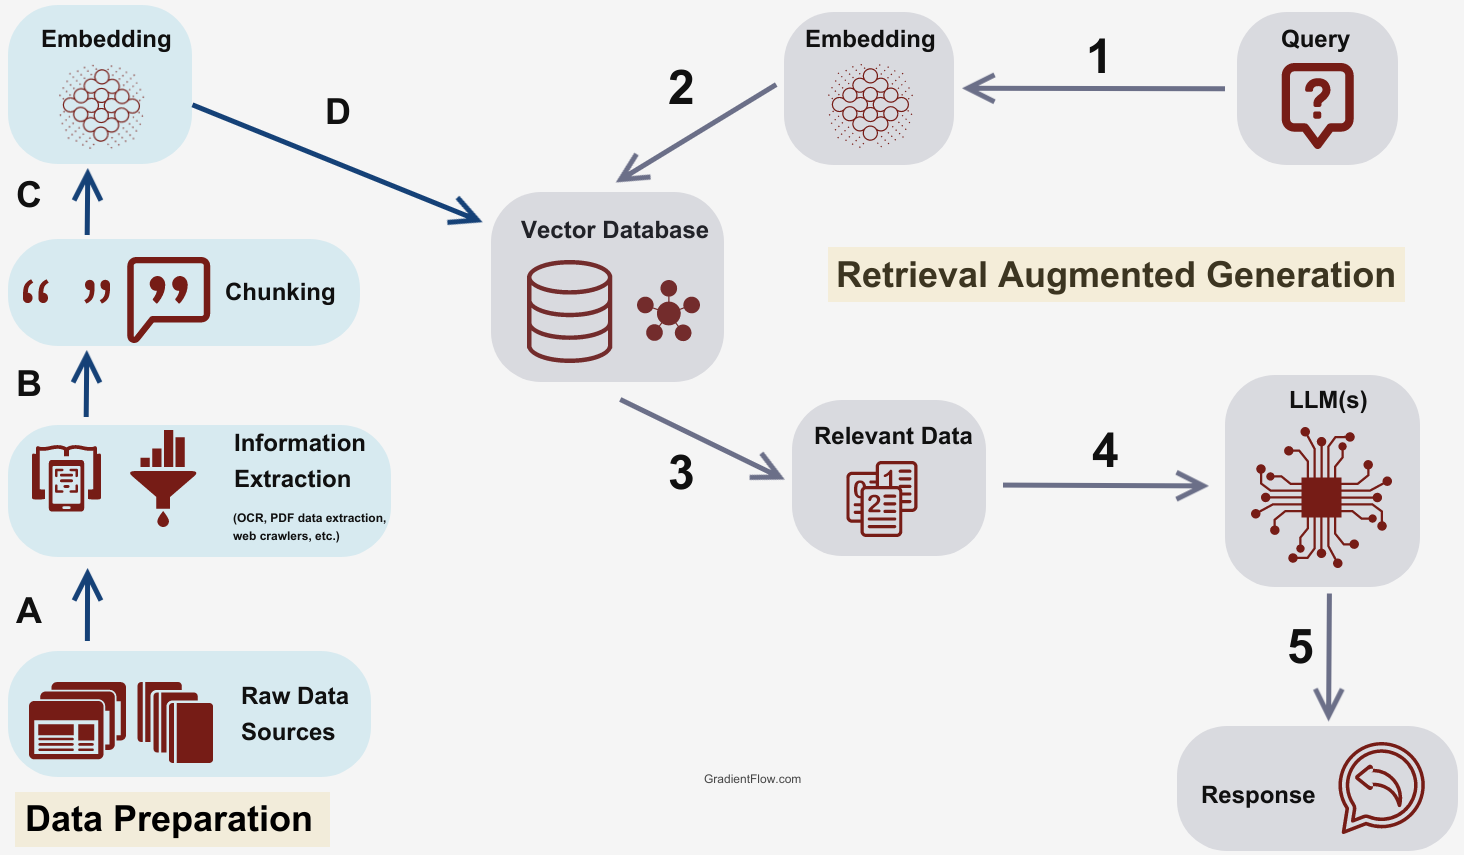

*Fuente: Gradient Flow (2023), «Best practices in retrieval augmented generation». La misma figura abre el cuaderno de RAG con datos del INBio.*

| En la figura | En este laboratorio | Paso |
| --- | --- | --- |
| **A.** Raw data sources | el índice web de actas y sus PDF | 2 |
| **B.** Information extraction | `pypdf` extrae el texto; una expresión regular saca participantes y cargos | 3 |
| **C.** Chunking | `SentenceSplitter` de LlamaIndex parte el texto en fragmentos | 3 |
| **D.** Embedding → Vector database | el **codificador** convierte cada fragmento en un vector; Neo4j lo guarda con su índice vectorial | 4 y 5 |
| **1.** Query | la pregunta | 9 |
| **2.** Embedding | el **mismo codificador** convierte la pregunta en un vector | 7 |
| **3.** Relevant data | búsqueda vectorial **más el camino en el grafo** (su TODO 5) | 7 |
| **4.** LLM | el **generador** recibe instrucciones, hechos, fragmentos y pregunta | 8 |
| **5.** Response | la respuesta, que debe citar el acta | 9 |

Una opción es que la base de datos sea solo una *vector database*: guarda vectores y devuelve los más parecidos. Aquí, en cambio, Neo4j guarda los vectores **y las relaciones**. Por eso el paso 3 no devuelve solo texto parecido, sino también hechos que se alcanzan recorriendo aristas: quién presidió, qué fragmento sigue. Esa es la diferencia entre RAG y **GraphRAG**.


### 8.2 El modelo codificador

El codificador (*encoder*) convierte un texto en **un solo vector** que representa su significado. No genera texto, solo condifica la entrada en una representación llamada embedding. El que usamos en este laboratorio pertenece a la familia de BERT y funciona así:

```mermaid
flowchart LR
  T["Texto<br/>«¿Quién preside la sesión 61-2026?»"] --> K["Tokenizador<br/>▁Quién · ▁pre · side · ▁la · ▁sesión ..."]
  K --> E["Codificador<br/>12 capas; cada token mira<br/>a todos los demás, en ambas direcciones"]
  E --> V["Un vector por token<br/>(384 números cada uno)"]
  V --> M["Promedio<br/>(mean pooling)"]
  M --> R["Un vector de 384<br/>para todo el texto"]
```

Cuatro reglas que importan para la base de datos:

1. **El mismo codificador para todo.** Los fragmentos (paso 4) y la pregunta (paso 7) se convierten con el mismo modelo. Si se mezclaran dos codificadores, sus vectores vivirían en espacios de representaciones distintos y la similitud coseno entre ellos no significaría nada.
2. **La dimensión la fija el codificador.** MiniLM produce un vector de 384, y por eso el índice vectorial de Neo4j se creó con `vector.dimensions: 384`. Cambiar de codificador obliga a recrear el índice en la base de datos y a recalcular todos los vectores.
3. **Se calcula una vez por fragmento.** Los vectores de los fragmentos se guardan al cargar. 
4. **Tiene un límite de lectura.** Este codificador lee como máximo **128 tokens** por texto, y lo que sobra lo ignora. La celda siguiente mide cuánto se pierde.

In [ ]:
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer

tokenizador_codificador = AutoTokenizer.from_pretrained(EMBED_MODEL)
LIMITE_CODIFICADOR = SentenceTransformer(EMBED_MODEL).max_seq_length

pregunta_demo = "¿Quién preside la sesión 61-2026?"
print("Tokens del codificador:", tokenizador_codificador.tokenize(pregunta_demo))

largos = [len(tokenizador_codificador.tokenize(f["texto"])) for f in fragmentos]
recortados = sum(largo > LIMITE_CODIFICADOR for largo in largos)
print(f"\nEl codificador lee como máximo {LIMITE_CODIFICADOR} tokens por texto.")
print(f"Los fragmentos tienen entre {min(largos)} y {max(largos)} tokens: "
      f"{recortados} de {len(fragmentos)} superan el límite.")

vector_pregunta = embed_model.get_text_embedding(pregunta_demo)
ranking = sorted(((coseno(vector_pregunta, f["embedding"]), f["id"]) for f in fragmentos), reverse=True)
print("\nLos tres fragmentos más parecidos, calculados en Python con todos los vectores:")
print("   fragmento   coseno   (1 + coseno) / 2")
for similitud, fragmento_id in ranking[:3]:
    print(f"   {fragmento_id:<10}  {similitud:.3f}    {(1 + similitud) / 2:.3f}")

**Observe la salida.**

- **Recorte.** Un fragmento que supera el límite queda representado solo por su comienzo. Todo lo que el fragmento dice después de esos tokens no influye en su vector. Esto explica en parte por qué la búsqueda vectorial confunde actas: sus comienzos son casi idénticos.
- **Escala del score.** Compare la última columna con la línea «Solo vector» del paso 7. Neo4j no reporta el coseno tal cual, sino **(1 + coseno) / 2**, que siempre queda entre 0 y 1. El orden de los resultados es el mismo.
- **Qué hace el índice.** El cálculo en Python recorre **todos** los vectores. Con 15 fragmentos es inmediato, pero con millones no lo sería. El índice vectorial de Neo4j organiza los vectores para encontrar los más cercanos sin compararlos uno por uno, igual que un índice B-tree evita recorrer toda una tabla.

### 8.3 El modelo generador

El generador (*decoder*) es el que escribe. Recibe un texto y **predice el siguiente token**. Luego agrega ese token al texto y vuelve a predecir, una y otra vez. A eso se le llama generación **autorregresiva**:

```mermaid
flowchart LR
  P["Texto hasta ahora<br/>(instrucciones + contexto + pregunta<br/>+ lo ya generado)"] --> G["Generador<br/>24 capas; cada token mira<br/>solo a los anteriores"]
  G --> D["Probabilidad de cada uno<br/>de los ~152 000 tokens posibles"]
  D --> S["Elegir el más probable<br/>(do_sample=False)"]
  S -->|"agregar y repetir"| P
  S -->|"token de fin o 96 tokens"| F["Respuesta"]
```

| | Codificador (MiniLM) | Generador (Qwen2.5) |
| --- | --- | --- |
| Familia | tipo BERT (*encoder*) | tipo GPT (*decoder*) |
| Cómo lee | cada token ve a todos, antes y después | cada token ve solo a los anteriores |
| Qué produce | un vector de 384 números | texto, token por token |
| Cuántas veces corre | una vez por texto | una vez **por cada token** de la respuesta |
| Cuánto texto lee | 128 tokens | hasta 32 768 tokens |
| Tamaño | ~118 millones de parámetros | ~494 millones de parámetros |
| Para qué sirve aquí | **buscar** | **redactar** |

**Instruct y la plantilla de chat.** La versión *Instruct* se ajustó después del preentrenamiento para seguir instrucciones en forma de conversación, con tres roles: `system` (las reglas), `user` (el pedido) y `assistant` (la respuesta). La función `apply_chat_template` convierte esa conversación en el texto con marcas especiales que el modelo espera. En la sección 8.5 verá ese texto completo.

**Sin reentrenar.** Hay dos maneras de que un modelo resuelva una tarea nueva:

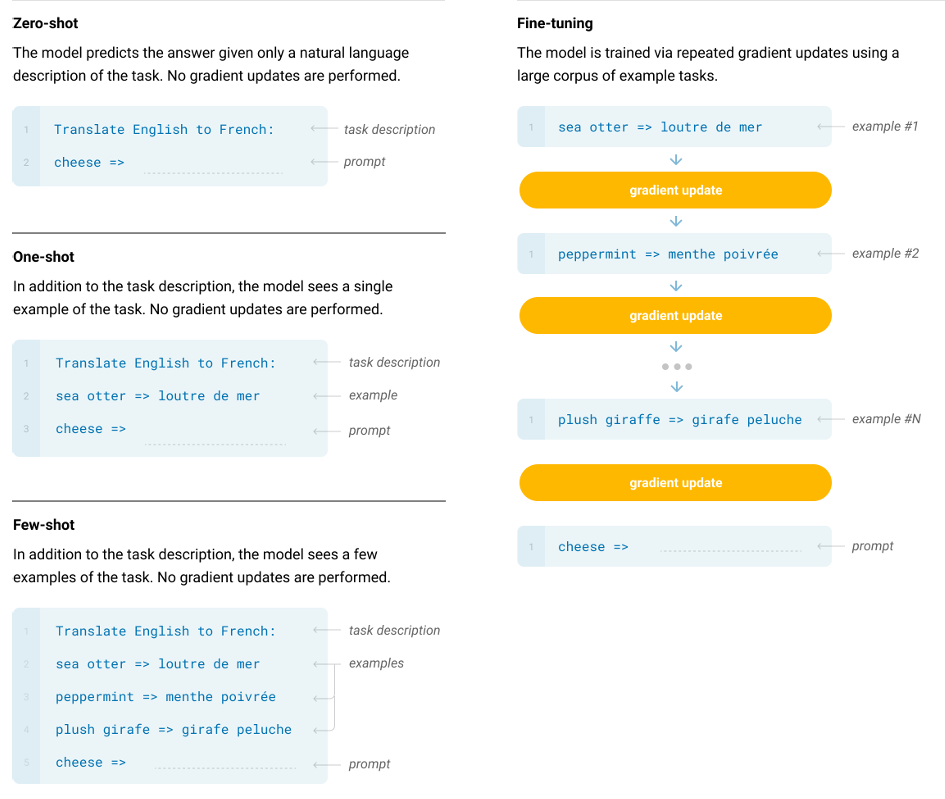

*Fuente: Brown et al. (2020), «Language Models are Few-Shot Learners», figura 2.3. Tomada del cuaderno «Low-Resource LLM» (KHIPU 2025).*

- **Ajuste fino** (*fine-tuning*, a la derecha) cambia los parámetros del modelo con muchos ejemplos (*gradient update*). Es costoso, y cada acta nueva obligaría a repetirlo. El ejemplo del INBio afinó Mistral-7B con sus datos.
- **Zero-shot** (arriba a la izquierda) solo describe la tarea en las instrucciones, sin cambiar ningún parámetro.

Este laboratorio usa **zero-shot más RAG**: la tarea va en `INSTRUCCIONES` y el conocimiento llega en el contexto recuperado. Cuando se publique el acta 62-2026, basta con cargarla en Neo4j; el modelo queda igual.

La celda siguiente carga el generador y lo muestra en acción: cómo corta una pregunta en tokens, qué probabilidades asigna al token siguiente y cómo arma una frase eligiendo, en cada paso, el token más probable. La primera ejecución tarda unos segundos.

In [ ]:
import torch
from transformers import AutoModelForCausalLM

tokenizador = AutoTokenizer.from_pretrained(MODELO_ID)
modelo = AutoModelForCausalLM.from_pretrained(MODELO_ID)
modelo.eval()
print(f"{MODELO_ID}: {sum(p.numel() for p in modelo.parameters()) / 1e6:.0f} millones de parámetros")

tokens_pregunta = tokenizador(pregunta_demo)["input_ids"]
print("Tokens del generador:", [tokenizador.decode([t]) for t in tokens_pregunta])

inicio = "El Concejo Municipal de Belén aprobó"
secuencia = tokenizador(inicio, return_tensors="pt")["input_ids"]
with torch.no_grad():
    probabilidades = modelo(input_ids=secuencia).logits[0, -1].softmax(-1)
print(f"\nDespués de «{inicio}», los cinco tokens más probables son:")
for probabilidad, token in zip(*probabilidades.topk(5)):
    print(f"   {tokenizador.decode([int(token)])!r:<16} {float(probabilidad):.3f}")

print("\nGeneración autorregresiva, eligiendo siempre el más probable:")
for paso in range(1, 9):
    with torch.no_grad():
        siguiente = modelo(input_ids=secuencia).logits[0, -1].argmax()
    secuencia = torch.cat([secuencia, siguiente.view(1, 1)], dim=1)
    print(f"   paso {paso}: {tokenizador.decode(secuencia[0])}")

**Observe la salida.**

- **Dos tokenizadores distintos.** El codificador y el generador cortan la misma pregunta de forma diferente: cada modelo trae su propio vocabulario. Por eso nunca se mezclan los tokens de uno con los del otro.
- **La continuación suena bien, pero no viene de las actas.** El modelo continúa la frase con lo que es **probable** en el idioma, no con lo que el Concejo aprobó de verdad. Esa misma maquinaria, sin contexto, es la que produce alucinaciones. RAG no cambia el modelo: cambia el texto que el modelo tiene delante.
- **Determinismo.** Con `do_sample=False` (decodificación *voraz*), la misma entrada produce siempre la misma salida. Eso permite comparar resultados entre equipos.

### 8.4 LangGraph: el grafo de control

LangGraph organiza el flujo de un sistema basado en agentes como un **grafo de control**. Sus nodos son funciones, sus aristas dicen qué función sigue y un **estado** (un diccionario) viaja de nodo en nodo. Cada nodo lee el estado y devuelve solo los campos que cambió.

```mermaid
flowchart LR
  S((inicio)) --> R["recuperar<br/>codificador + Neo4j"]
  R -->|"hay contexto"| D["redactar<br/>generador"]
  R -->|"no hay contexto"| V["vacío"]
  D --> E((fin))
  V --> E
```

| Momento | `pregunta` | `contextos` | `respuesta` |
| --- | --- | --- | --- |
| al entrar | la pregunta | `[]` | `""` |
| después de `recuperar` | igual | los fragmentos del TODO 5, con sus hechos | `""` |
| después de `redactar` | igual | igual | el texto que generó el modelo |

- `recuperar` llama a la función del TODO 5. Ahí trabajan el codificador y Neo4j: es la «R» de RAG.
- `redactar` arma las instrucciones con los **hechos del grafo** (tipo, fecha y cargos de cada acta) y los **fragmentos**, y llama al generador. Son la «A» y la «G».
- La arista que sale de `recuperar` es **condicional**: la decide la función `decidir`. Si no se recuperó nada (por ejemplo, porque el TODO 5 sigue pendiente), el flujo va a `vacío` y **no llama al modelo**. Es preferible no responder a responder sin fundamento.

**¿Por qué no una función de Python común?** Para tres pasos alcanzaría. Pero el flujo de un sistema RAG crece rápido: reintentar con más fragmentos si la respuesta no cita un acta, verificar la respuesta con otro paso, consultar otra fuente. Con LangGraph, cada paso nuevo es un nodo y una arista, y el flujo completo se puede dibujar. La celda siguiente dibuja el grafo **tal como LangGraph lo compiló**; compárelo con el diagrama de arriba.

Recuerde la aclaración de la sección 6: este grafo de **control** no tiene nada que ver con el grafo de **datos** de Neo4j, aunque ambos se llamen grafo.

In [ ]:
from typing import TypedDict

from IPython.display import Markdown, display
from langgraph.graph import END, START, StateGraph

INSTRUCCIONES = (
    "Usted responde preguntas sobre actas del Concejo Municipal de Belén. "
    "Responda en español, en una o dos oraciones, usando solamente los hechos y fragmentos dados. "
    "Cite el id del acta. Los hechos del grafo son datos verificados: si responden la pregunta, úselos primero. "
    "Si la información no aparece, diga que no aparece en el contexto."
)


class Estado(TypedDict):
    pregunta: str
    contextos: list
    respuesta: str


def hechos_del_grafo(contextos: list) -> str:
    lineas, vistas = [], set()
    for ctx in contextos:
        if ctx["acta"] in vistas:
            continue
        vistas.add(ctx["acta"])
        cargos = "; ".join(f"{p['cargo']}: {p['nombre']}" for p in ctx["participantes"] if p.get("cargo"))
        lineas.append(f"- Acta {ctx['acta']}: sesión {ctx['tipo']} del {ctx['fecha']}. {cargos or 'Sin cargos registrados.'}")
    return "\n".join(lineas)


def armar_prompt(pregunta: str, contextos: list) -> str:
    textos = "\n---\n".join(f"[{c['fragmento']}] {c['texto'][:700]}" for c in contextos)
    pedido = (
        f"Fragmentos:\n{textos}\n\n"
        f"Hechos del grafo:\n{hechos_del_grafo(contextos)}\n\n"
        f"Pregunta: {pregunta}"
    )
    mensajes = [{"role": "system", "content": INSTRUCCIONES}, {"role": "user", "content": pedido}]
    return tokenizador.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)


def redactar_con_modelo(pregunta: str, contextos: list) -> str:
    entradas = tokenizador(armar_prompt(pregunta, contextos), return_tensors="pt")
    with torch.no_grad():
        salida = modelo.generate(**entradas, max_new_tokens=96, do_sample=False,
                                 pad_token_id=tokenizador.eos_token_id)
    return tokenizador.decode(salida[0, entradas["input_ids"].shape[-1]:], skip_special_tokens=True).strip()


def nodo_recuperar(estado: Estado) -> dict:
    return {"contextos": recuperar(estado["pregunta"])}


def nodo_redactar(estado: Estado) -> dict:
    return {"respuesta": redactar_con_modelo(estado["pregunta"], estado["contextos"])}


def nodo_vacio(estado: Estado) -> dict:
    return {"respuesta": "No se recuperó contexto; el modelo no se consultó."}


def decidir(estado: Estado) -> str:
    return "redactar" if estado["contextos"] else "vacio"


flujo = StateGraph(Estado)
flujo.add_node("recuperar", nodo_recuperar)
flujo.add_node("redactar", nodo_redactar)
flujo.add_node("vacio", nodo_vacio)
flujo.add_edge(START, "recuperar")
flujo.add_conditional_edges("recuperar", decidir, {"redactar": "redactar", "vacio": "vacio"})
flujo.add_edge("redactar", END)
flujo.add_edge("vacio", END)
aplicacion = flujo.compile()
print("LangGraph compilado: inicio → recuperar → (redactar | vacío) → fin")
display(Markdown("```mermaid\n" + aplicacion.get_graph().draw_mermaid() + "\n```"))


def preguntar(pregunta: str) -> dict:
    final = aplicacion.invoke({"pregunta": pregunta, "contextos": [], "respuesta": ""})
    print(f"\nPregunta: {pregunta}")
    for c in final["contextos"]:
        print(f"   contexto {c['fragmento']:<10} score={c['score']:.3f}")
    print(f"Respuesta: {final['respuesta']}")
    return final

### 8.5 Lo que el generador recibe de verdad

La «A» de RAG es solo texto: los hechos y los fragmentos se **pegan** en las instrucciones. La celda siguiente imprime el texto exacto que recibe el generador para la primera pregunta del paso 9, con las marcas de la plantilla de chat (`<|im_start|>system`, `<|im_start|>user`, `<|im_start|>assistant`).

Busque en la salida tres cosas:

1. las reglas de `INSTRUCCIONES`, bajo `system`;
2. los fragmentos que encontró el índice vectorial (el **texto**);
3. los «Hechos del grafo», que salen de recorrer `PARTICIPA_EN` en su TODO 5 (la **estructura**).

El modelo no ve Neo4j ni los vectores: solo ve este texto. Si un dato no está aquí, el modelo no tiene de dónde sacarlo.

In [ ]:
if estado_todos["TODO 5"] != "OK":
    print("PENDIENTE: esta celda necesita el TODO 5 para recuperar contexto.")
else:
    ejemplo = "Según el acta 61-2026, ¿quién preside la sesión?"
    prompt = armar_prompt(ejemplo, recuperar(ejemplo))
    print(prompt)
    print(f"\nTotal: {len(tokenizador(prompt)['input_ids'])} tokens, de los 32 768 que admite la ventana de contexto.")

## Paso 9 — Preguntas y verificación final

Tres preguntas:

1. una cuya respuesta está en los **hechos del grafo** (el cargo);
2. una cuya respuesta está en el **texto** (qué acta se somete a aprobación);
3. una que **no nombra un acta**, así que solo cuenta la búsqueda vectorial.

La verificación revisa que la respuesta no cite un acta que no estaba en el contexto. Que la respuesta sea **correcta** no lo puede decidir el código: eso le toca a usted, en el informe.

In [ ]:
preguntas = [
    "Según el acta 61-2026, ¿quién preside la sesión?",
    "En el acta 61-2026, ¿qué acta anterior se somete a aprobación?",
    "¿En qué sesión se acordó enviar una nota de pésame?",
]
resultados = [preguntar(p) for p in preguntas]

print("\n=== Verificación final ===")
if estado_todos["TODO 5"] == "OK":
    for r in resultados:
        exigir(len(r["contextos"]) > 0, f"«{r['pregunta'][:40]}…» recuperó contexto")
        permitidas = set()
        for c in r["contextos"]:
            permitidas.add(c["acta"])
            permitidas.update(re.findall(r"\d{2}-\d{4}", c["texto"]))
        citadas = set(re.findall(r"\d{2}-\d{4}", r["respuesta"]))
        exigir(citadas <= permitidas, f"la respuesta no cita actas ajenas al contexto ({sorted(citadas) or 'ninguna'})")
    presidencia = [p["nombre"] for a in actas if a["id"] == "61-2026" for p in a["personas"] if p["cargo"] == "Presidente"]
    acierto = bool(presidencia) and presidencia[0].split()[0] in resultados[0]["respuesta"]
    print(f"OBSERVACIÓN: la primera respuesta {'sí' if acierto else 'no'} nombra a quien el grafo registra como Presidente.")

print()
for todo, estado in estado_todos.items():
    print(f"   {todo}: {estado}")
if all(e == "OK" for e in estado_todos.values()):
    print("\nOK: el laboratorio está completo. Pase a las preguntas del informe.")
else:
    print("\nAún hay TODO pendientes. Complételos en orden y ejecute de nuevo desde el paso 5.")

## Para el informe

Pegue salidas de este cuaderno; no las transcriba a mano. Máximo cuatro páginas.

1. ¿Cuántos documentos publica el índice y cuántas actas entraron al grafo? ¿Qué haríamos si solo contamos con un PDF escaneado.
2. Incluya la captura del navegador de Neo4j (paso 6.3). Explique por qué `cargo` es una propiedad de `PARTICIPA_EN` y no de `Persona`.
3. Pegue sus consultas de los TODO 3 y 4, con su resultado. Compárelas con el SQL equivalente: ¿cuántos `JOIN` necesitaría un tercer salto?
4. ¿Qué pasó, o qué habría pasado, si en el TODO 1 usaba `CREATE` en lugar de `MERGE`? 
5. Con la salida del TODO 5, compare «solo vector» con «vector + acta». ¿Por qué usando solo el vector puede equivocarse de acta? Use la salida del paso 8.2: ¿qué papel juega que el codificador lea solo los primeros 128 tokens de cada fragmento?
6. Para cada una de las tres preguntas del paso 9, diga si la respuesta es correcta según el contexto recuperado. Si el modelo afirma algo que no está en ese contexto, señálelo: identificar una alucinación es parte de la evaluación, no un defecto a ocultar.


## Glosario

| Término | Significado |
| --- | --- |
| Grafo de propiedades | modelo con nodos, relaciones con tipo y dirección, y propiedades en ambos |
| Salto | recorrer una relación de un nodo a otro |
| Idempotente | que repetir la operación deja el mismo resultado |
| Token | unidad de texto con que trabaja un modelo de lenguaje: una palabra o parte de ella |
| Modelo preentrenado | modelo que ya aprendió de grandes volúmenes de texto y se usa sin entrenarlo de nuevo |
| Embedding | vector que representa el significado de un texto |
| Similitud coseno | medida de cercanía entre dos vectores, entre −1 y 1 |
| Ventana de contexto | cantidad de texto que el modelo puede leer en una consulta |
| Alucinación | respuesta del modelo que suena plausible, pero no se apoya en los datos |
| Modelo codificador | modelo que lee un texto completo y lo resume en un vector; sirve para buscar (aquí, MiniLM) |
| Modelo generador | modelo que escribe texto prediciendo un token a la vez; sirve para redactar (aquí, Qwen2.5) |
| Generación autorregresiva | agregar cada token generado a la entrada y volver a predecir el siguiente |
| Decodificación voraz | elegir siempre el token más probable (`do_sample=False`); da salidas deterministas |
| Plantilla de chat | Template de formato con roles `system`, `user` y `assistant` que espera un modelo *Instruct* |
| Zero-shot | resolver una tarea solo con instrucciones, sin cambiar los parámetros del modelo |
| Ajuste fino | reentrenar un modelo con ejemplos de la tarea; cambia sus parámetros |
| RAG | recuperar texto, agregarlo a las instrucciones y generar la respuesta a partir de él |
| GraphRAG | RAG que agrega al contexto hechos que salen de las relaciones del grafo |
| LangGraph | biblioteca que organiza un programa como grafo de control: nodos (funciones), aristas y un estado compartido |